# Tutorial 2: Valores nulos: técnicas complementares (e duplicados)

**Autor:** Fabio Stein

Este tutorial **complementa** o [Tutorial 1](tutorial_data_wrangling.ipynb), que apresentou os nulos, os nulos disfarçados, o `dropna`, o `fillna` com a mediana e os duplicados. Aqui você vai aprofundar: os diferentes tipos de nulo do pandas, como **investigar por que** um dado falta, como **apagar com critério**, como **preencher de acordo com o tipo da variável**, como tratar **séries de tempo**, quando **não** preencher e como escolher **qual duplicado manter**.

**Como usar:** execute uma célula por vez (`Shift + Enter`). Os quadros **📚 Teoria (opcional)** podem ser pulados na primeira leitura; os quadros **🔍 Passo a passo** explicam o código.

| Parte | Assunto |
|---|---|
| 0 | Preparar o ambiente |
| 1 | Os quatro "nulos" do pandas |
| 2 | Diagnóstico: por que o dado falta? |
| 3 | Apagar com critério |
| 4 | Preencher conforme o tipo de variável |
| 5 | Séries de tempo: `ffill`, `bfill` e `interpolate` |
| 6 | Quando NÃO preencher |
| 7 | Duplicados: qual registro manter? |
| 8 | Validar o preenchimento |
| 9 | Exercícios |

## Parte 0: Preparar o ambiente

Usamos as mesmas bibliotecas do Tutorial 1. Se precisar instalar:

```
pip install numpy pandas matplotlib seaborn jupyter
```

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme()
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)
print("Tudo pronto! pandas", pd.__version__)

Tudo pronto! pandas 3.1.1


## Parte 1: Os quatro "nulos" do pandas

O pandas reconhece quatro formas de "valor ausente":

| Valor | De onde vem | Onde aparece |
|---|---|---|
| `None` | o "nada" do próprio Python | listas e colunas de texto |
| `np.nan` | *Not a Number*, do NumPy | colunas de números decimais (`float`) |
| `pd.NA` | o nulo "moderno" do pandas | tipos anuláveis como `Int64`, `boolean` e `string` |
| `pd.NaT` | *Not a Time* | colunas de datas |

A boa notícia: **`isna()` reconhece todos eles.**

In [2]:
s = pd.Series([1.5, None, np.nan, pd.NA, pd.NaT, "texto"])
pd.DataFrame({"valor": s, "isna": s.isna()})

,valor,isna
0,1.5,False
1,None,True
2,NaN,True
3,<NA>,True
4,NaT,True
5,texto,False


### 1.1 Uma pegadinha: `NaN` não é igual a `NaN`

### 🔍 Passo a passo
Pela regra dos números de ponto flutuante (padrão IEEE 754), `NaN` **não é igual a nada**, nem a ele mesmo. Por isso, **nunca** procure nulos com `== np.nan`: o resultado é sempre `False`. Use sempre `isna()`.

In [3]:
print("np.nan == np.nan ->", np.nan == np.nan)

serie = pd.Series([10, np.nan, 30])
print("Nulos achados com == np.nan:", (serie == np.nan).sum())
print("Nulos achados com isna():   ", serie.isna().sum())

np.nan == np.nan -> False
Nulos achados com == np.nan: 0
Nulos achados com isna():    1


### 1.2 Inteiros com nulo viram decimais

### 🔍 Passo a passo
O tipo `int64` do NumPy **não tem como guardar um nulo**. Quando um nulo aparece numa coluna de inteiros, o pandas converte tudo para `float64` (o 2 vira 2.0). O tipo **`Int64`** (com **I maiúsculo**) é a versão **anulável**: continua inteiro e guarda o nulo como `pd.NA`.

In [4]:
filhos = pd.Series([2, 0, None, 1])
print(filhos.dtype)
print(filhos.tolist())

filhos_int = filhos.astype("Int64")
print(filhos_int.dtype)
print(filhos_int.tolist())

float64
[2.0, 0.0, nan, 1.0]
Int64
[2, 0, <NA>, 1]


## Parte 2: Diagnóstico: por que o dado falta?

Vamos usar uma **pesquisa de satisfação de clientes** com 600 respostas. Como sempre, os dados são sintéticos e os nulos foram colocados de propósito, com **padrões diferentes**.

### 📚 Teoria (opcional): os mecanismos de ausência
Rubin [1] classificou os nulos em três mecanismos (visto no Tutorial 1):
- **MCAR** (*completamente ao acaso*): a falta não depende de nada. Ex.: uma folha do questionário se perdeu.
- **MAR** (*ao acaso, dado o que se observa*): a falta depende de **outra coluna** que conhecemos. Ex.: pessoas mais velhas deixam mais a renda em branco.
- **MNAR** (*não ao acaso*): a falta depende do **próprio valor** que falta. Ex.: quem ganha muito esconde a renda.

Não existe um teste que prove o mecanismo [2][4]. O que dá para fazer é **procurar pistas**, que é o objetivo desta parte.

Não se preocupe em entender a célula de criação dos dados. Só execute.

In [5]:
rng = np.random.default_rng(303)
n = 600
escolaridades = ["Fundamental", "Médio", "Técnico", "Superior", "Pós-graduação"]
satisfacoes = ["Muito insatisfeito", "Insatisfeito", "Neutro", "Satisfeito", "Muito satisfeito"]

idade = rng.integers(18, 81, n)
pesquisa = pd.DataFrame({
    "cliente_id": range(1, n + 1),
    "idade": idade.astype(float),
    "renda": (rng.lognormal(8.1, 0.5, n) + idade * 25).round(-1),
    "escolaridade": rng.choice(escolaridades, n, p=[0.15, 0.35, 0.15, 0.25, 0.10]),
    "num_filhos": rng.poisson(1.3, n).astype(float),
    "cidade": rng.choice(["Curitiba", "Londrina", "Maringá", "Cascavel"], n, p=[0.45, 0.25, 0.20, 0.10]),
    "satisfacao": rng.choice(satisfacoes, n, p=[0.05, 0.10, 0.25, 0.40, 0.20]),
    "telefone": [f"(41) 9{rng.integers(1000, 9999)}-{rng.integers(1000, 9999)}" for _ in range(n)],
    "email": [f"cliente{i}@exemplo.com" for i in range(1, n + 1)],
    "apelido": rng.choice(["Zé", "Nina", "Beto", "Lu"], n),
    "observacao": np.nan,
})
pesquisa = pesquisa.astype({"escolaridade": object, "cidade": object, "satisfacao": object,
                            "telefone": object, "email": object, "apelido": object})

# MAR: a renda falta muito mais entre quem tem 60 anos ou mais
p_falta_renda = np.where(pesquisa["idade"] >= 60, 0.40, 0.07)
pesquisa.loc[rng.random(n) < p_falta_renda, "renda"] = np.nan
# bloco "contato": quem pulou o telefone quase sempre pulou o e-mail também
pula_contato = rng.random(n) < 0.12
pesquisa.loc[pula_contato, ["telefone", "email"]] = np.nan
pesquisa.loc[rng.random(n) < 0.03, "email"] = np.nan
# MCAR: faltas ao acaso
for coluna, p in [("idade", 0.03), ("escolaridade", 0.06), ("num_filhos", 0.05),
                  ("cidade", 0.07), ("satisfacao", 0.08)]:
    pesquisa.loc[rng.random(n) < p, coluna] = np.nan
# coluna quase vazia e respostas totalmente em branco
pesquisa.loc[rng.random(n) < 0.75, "apelido"] = np.nan
em_branco = [17, 230, 411, 598]
pesquisa.loc[em_branco, pesquisa.columns.drop("cliente_id")] = np.nan

pesquisa.to_csv("pesquisa_clientes.csv", index=False)
df = pd.read_csv("pesquisa_clientes.csv")
print("Linhas:", len(df))
(df.isna().mean() * 100).round(1).sort_values(ascending=False)

Linhas: 600


observacao      100.0
apelido          72.5
renda            19.0
email            14.0
telefone         11.8
satisfacao        7.7
escolaridade      7.2
cidade            6.0
num_filhos        5.7
idade             4.7
cliente_id        0.0
dtype: float64

### 2.1 Quantos nulos cada linha tem?
Contar por **coluna** já é conhecido. Contar por **linha** revela outra coisa: respostas quase vazias, que talvez nem devam ser analisadas.

### 🔍 Passo a passo
- `df.isna().sum(axis=1)`: `axis=1` soma **ao longo das colunas**, ou seja, dá um total por linha.

1      84
2     279
3     153
4      58
5      15
6       6
7       1
10      4
Name: count, dtype: int64


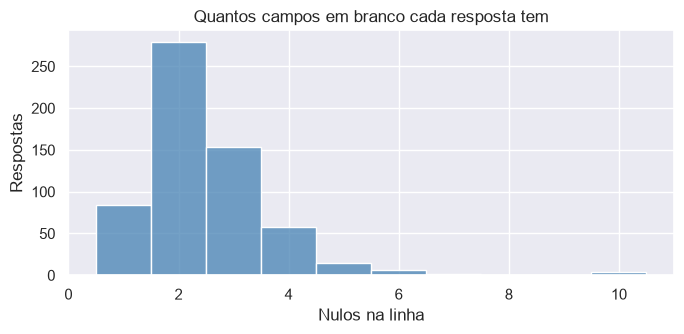

In [6]:
nulos_por_linha = df.drop(columns="cliente_id").isna().sum(axis=1)
print(nulos_por_linha.value_counts().sort_index())

plt.figure(figsize=(7, 3.5))
sns.histplot(nulos_por_linha, discrete=True, color="steelblue")
plt.title("Quantos campos em branco cada resposta tem")
plt.xlabel("Nulos na linha")
plt.ylabel("Respostas")
plt.tight_layout()
plt.show()

A maioria das respostas tem de 1 a 3 nulos. Ninguém tem zero, porque `observacao` está vazia em todas. Na ponta direita estão as **4 respostas totalmente em branco**: vamos tratá-las na Parte 3.

### 2.2 Os nulos andam juntos?

### 🔍 Passo a passo
1. `df.isna()` vira uma tabela de `True`/`False`.
2. `.corr()` calcula a **correlação** entre essas colunas: perto de **1** quer dizer "quando um falta, o outro também falta".
3. Tiramos `observacao` (sempre nula, sem variação) e as linhas em branco, que juntariam tudo artificialmente.

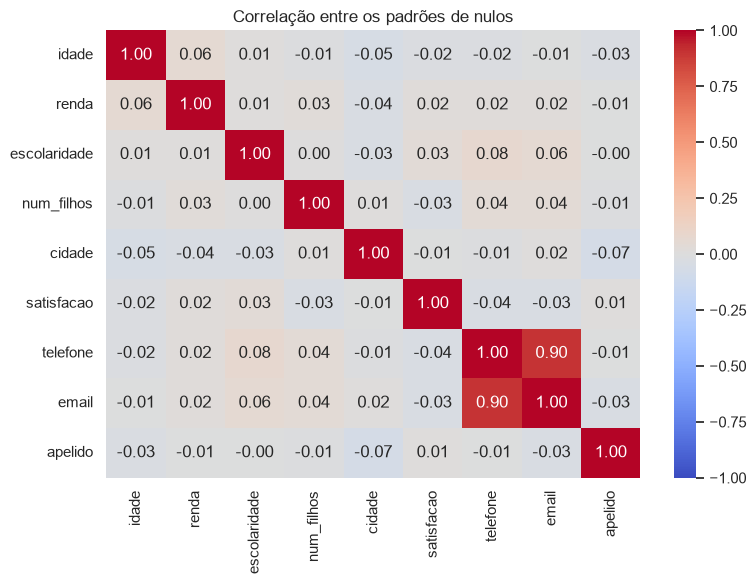

In [7]:
padrao = df.drop(index=em_branco, columns=["cliente_id", "observacao"]).isna()
corr_nulos = padrao.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_nulos, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlação entre os padrões de nulos")
plt.tight_layout()
plt.show()

### Como ler o mapa
- `telefone` × `email` tem correlação alta: as pessoas pulam o **bloco de contato** inteiro. Isso sugere um problema no **questionário** (o bloco era opcional ou ficava escondido), não nas pessoas.
- As outras correlações ficam perto de zero: as faltas não andam juntas.

### 2.3 Quem não informou a renda é diferente de quem informou?
Se a falta for MCAR, quem deixou a renda em branco deve ser **parecido** com quem respondeu. Se for diferente em alguma outra coluna, temos uma **pista de MAR**.

In [8]:
falta_renda = df["renda"].isna()
comparacao = pd.DataFrame({
    "informou a renda": df.loc[~falta_renda, ["idade", "num_filhos"]].mean(),
    "não informou": df.loc[falta_renda, ["idade", "num_filhos"]].mean(),
}).round(2)
comparacao

,informou a renda,não informou
idade,46.71,61.34
num_filhos,1.24,1.39


In [9]:
faixa_etaria = pd.cut(df["idade"], bins=[17, 39, 59, 80], labels=["18 a 39", "40 a 59", "60 ou mais"])
(df["renda"].isna().groupby(faixa_etaria, observed=True).mean() * 100).round(1).rename("% sem renda")

idade
18 a 39        5.6
40 a 59       10.0
60 ou mais    37.6
Name: % sem renda, dtype: float64

**Pista forte de MAR:** quem não informou a renda é, em média, bem mais velho, e na faixa de 60 anos ou mais a falta é várias vezes maior. Consequência prática: preencher a renda com a mediana **geral** puxaria a renda dos idosos para a dos jovens. Na Parte 4 vamos preencher **por faixa etária**.

O número de filhos, por outro lado, é parecido nos dois grupos: nada indica que ele explique a falta.

## Parte 3: Apagar com critério

O `dropna()` sem parâmetros apaga **qualquer linha com pelo menos um nulo**. Nesta pesquisa, isso é um desastre:

In [10]:
print("Linhas originais:          ", len(df))
print("Linhas depois de dropna(): ", len(df.dropna()))

Linhas originais:           600
Linhas depois de dropna():  0


Zero! A coluna `observacao` está vazia em todas as linhas, então **toda** linha tem pelo menos um nulo. Os parâmetros do `dropna` existem para evitar isso.

### 🔍 Os parâmetros do `dropna`
| Parâmetro | O que faz |
|---|---|
| `axis=1` | apaga **colunas** em vez de linhas |
| `how="all"` | só apaga se **todos** os valores forem nulos (o padrão é `"any"`, basta um) |
| `thresh=k` | mantém só o que tem **pelo menos k valores não nulos** |
| `subset=[...]` | só olha para essas colunas na hora de decidir |

### 3.1 Colunas vazias ou quase vazias
Regra prática: coluna com **mais de 50% de nulos** raramente vale a pena preencher. Preencher metade de uma coluna é **inventar** metade dela.

In [11]:
pct_nulos = df.isna().mean()
print(pct_nulos[pct_nulos > 0.5].round(2))

df = df.dropna(axis=1, how="all")                       # apaga colunas 100% vazias
df = df.drop(columns=pct_nulos[pct_nulos > 0.5].index.drop("observacao"))   # e as com mais de 50%
print("Colunas restantes:", list(df.columns))

apelido       0.72
observacao    1.00
dtype: float64
Colunas restantes: ['cliente_id', 'idade', 'renda', 'escolaridade', 'num_filhos', 'cidade', 'satisfacao', 'telefone', 'email']


### 3.2 Linhas em branco
`how="all"` apaga só as linhas em que **todas** as colunas olhadas estão vazias. Usamos `subset` para ignorar o `cliente_id`, que nunca falta.

In [12]:
colunas_resposta = df.columns.drop("cliente_id")
antes = len(df)
df = df.dropna(subset=colunas_resposta, how="all")
print("Respostas em branco removidas:", antes - len(df))

Respostas em branco removidas: 4


### 3.3 `thresh`: exigir um mínimo de respostas
Com `thresh`, você diz **quantos valores preenchidos** a linha precisa ter para ficar. Veja quanto se perde com cada exigência:

In [13]:
total_colunas = df.shape[1]
for minimo in [total_colunas, total_colunas - 1, total_colunas - 2]:
    restam = len(df.dropna(thresh=minimo))
    print(f"Exigir {minimo} de {total_colunas} campos: ficam {restam} linhas ({restam / len(df):.0%})")

Exigir 9 de 9 campos: ficam 317 linhas (53%)
Exigir 8 de 9 campos: ficam 490 linhas (82%)
Exigir 7 de 9 campos: ficam 567 linhas (95%)


### 3.4 `subset`: só o que é essencial
Para uma análise de satisfação, sem a resposta de **satisfação** a linha não serve. As outras colunas podem ser preenchidas. Então apagamos olhando **só** essa coluna:

In [14]:
antes = len(df)
df = df.dropna(subset=["satisfacao"])
print(f"Removidas: {antes - len(df)} linhas ({(antes - len(df)) / antes:.1%}). Restam {len(df)}.")

Removidas: 42 linhas (7.0%). Restam 554.


## Parte 4: Preencher conforme o tipo de variável

### 📚 Teoria (opcional): escalas de medida
Stevens [5] classificou as variáveis pelo que faz sentido calcular com elas:

| Tipo | Exemplo | Faz sentido | Como preencher |
|---|---|---|---|
| **Contínua** | renda, altura | média, mediana | mediana (geral ou por grupo) |
| **Discreta** (contagem) | número de filhos | mediana, moda | moda ou mediana **arredondada** |
| **Nominal** (sem ordem) | cidade | só contar | moda, "Desconhecido" ou sorteio |
| **Ordinal** (com ordem) | escolaridade, satisfação | ordenar, mediana | mediana da **posição** |

### Antes de preencher: marque!
Guarde uma coluna dizendo **quais valores eram nulos**. Depois de preenchido, não dá mais para saber, e o fato de a pessoa **não ter respondido** pode ser uma informação útil para a análise [3].

In [15]:
for coluna in ["renda", "num_filhos", "cidade", "escolaridade", "idade"]:
    df[f"{coluna}_faltava"] = df[coluna].isna()
df.filter(like="_faltava").sum()

renda_faltava           101
num_filhos_faltava       29
cidade_faltava           30
escolaridade_faltava     35
idade_faltava            23
dtype: int64

### 4.1 Contínua: o perigo da distribuição com dois picos
Antes da pesquisa, um exemplo à parte: salários de uma empresa com **estagiários** e **gerentes**. Há dois grupos bem separados (uma distribuição **bimodal**).

In [16]:
rng_sal = np.random.default_rng(8)
cargo = np.array(["Estagiário"] * 300 + ["Gerente"] * 300)
salario = np.concatenate([rng_sal.normal(1800, 200, 300), rng_sal.normal(12000, 1500, 300)]).round(-1)
empresa = pd.DataFrame({"cargo": cargo, "salario": salario})
empresa.loc[rng_sal.random(600) < 0.15, "salario"] = np.nan

media = empresa["salario"].mean()
mediana = empresa["salario"].median()
perto = lambda v: empresa["salario"].between(v - 1000, v + 1000).sum()
print(f"Média:   R$ {media:9.2f}  -> salários reais a menos de R$ 1.000 dela: {perto(media)}")
print(f"Mediana: R$ {mediana:9.2f}  -> salários reais a menos de R$ 1.000 dela: {perto(mediana)}")

Média:   R$   6963.16  -> salários reais a menos de R$ 1.000 dela: 1
Mediana: R$   8735.00  -> salários reais a menos de R$ 1.000 dela: 22


A média cai no **vazio entre os dois grupos**: praticamente ninguém ganha esse valor. Preencher com ela cria pessoas que não existem. A mediana se sai um pouco melhor, mas também fica longe do centro dos dois grupos: cai na ponta de baixo dos salários de gerente. A saída é preencher **dentro do grupo** (como no Tutorial 1):

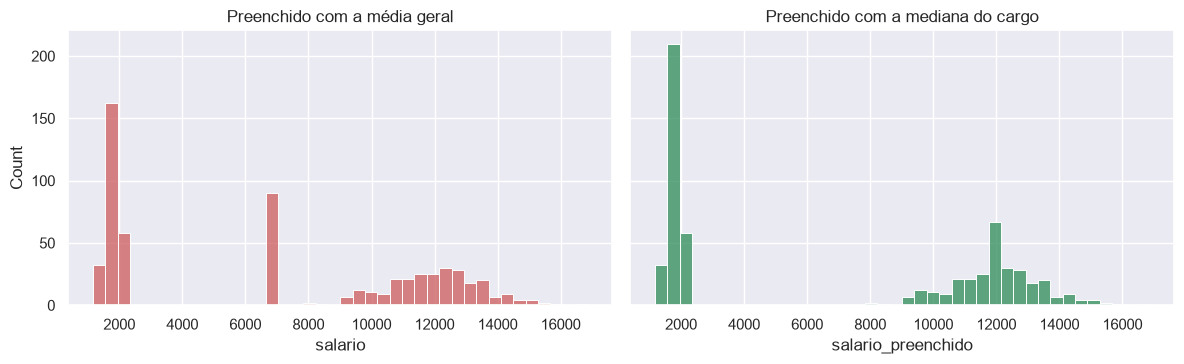

In [17]:
por_cargo = empresa.groupby("cargo")["salario"].transform("median")
empresa["salario_preenchido"] = empresa["salario"].fillna(por_cargo)

fig, eixos = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
sns.histplot(empresa["salario"].fillna(media), bins=40, ax=eixos[0], color="indianred")
eixos[0].set_title("Preenchido com a média geral")
sns.histplot(empresa["salario_preenchido"], bins=40, ax=eixos[1], color="seagreen")
eixos[1].set_title("Preenchido com a mediana do cargo")
plt.tight_layout()
plt.show()

No gráfico da esquerda aparece uma barra alta **no meio do nada**: são os salários inventados. No da direita, cada valor preenchido cai dentro do seu grupo.

Voltando à pesquisa: a Parte 2 mostrou que a renda falta mais entre os idosos (MAR). Então preenchemos com a **mediana da faixa etária**. A idade, que tem poucos nulos ao acaso, recebe a mediana geral antes.

In [18]:
df["idade"] = df["idade"].fillna(df["idade"].median())
df["faixa_etaria"] = pd.cut(df["idade"], bins=[17, 39, 59, 80], labels=["18 a 39", "40 a 59", "60 ou mais"])

renda_original = df["renda"].copy()      # guardamos para comparar na Parte 8
mediana_faixa = df.groupby("faixa_etaria", observed=True)["renda"].transform("median")
df["renda"] = df["renda"].fillna(mediana_faixa)

print(df.groupby("faixa_etaria", observed=True)["renda"].median().round(0))
print("Nulos restantes em renda:", df["renda"].isna().sum())

faixa_etaria
18 a 39       4110.0
40 a 59       4600.0
60 ou mais    5150.0
Name: renda, dtype: float64
Nulos restantes em renda: 0


### 4.2 Discreta: ninguém tem 1,26 filho

In [19]:
print("Média de filhos:   ", round(df["num_filhos"].mean(), 2))
print("Mediana de filhos: ", df["num_filhos"].median())
print("Moda de filhos:    ", df["num_filhos"].mode()[0])

Média de filhos:    1.26
Mediana de filhos:  1.0
Moda de filhos:     0.0


### 🔍 Passo a passo
- A **média** dá um número quebrado: preencher com ela cria famílias com "1,26 filho".
- A **moda** (`mode()`) é o valor mais frequente. Como pode haver empate, `mode()` devolve uma lista; `[0]` pega o primeiro.
- Se a mediana desse um valor quebrado (por exemplo 1,5, quando há um empate no meio), use `round()`.
- No fim, `astype("Int64")` deixa a coluna como inteiro de verdade (Parte 1.2).

In [20]:
df["num_filhos"] = df["num_filhos"].fillna(df["num_filhos"].mode()[0]).astype("Int64")
df["num_filhos"].value_counts().sort_index()

num_filhos
0    195
1    159
2    126
3     51
4     18
5      4
6      1
Name: count, dtype: Int64

### 4.3 Nominal: três opções
Para uma coluna sem ordem, como `cidade`, não existe média nem mediana. As opções são:

| Opção | Vantagem | Desvantagem |
|---|---|---|
| **Moda** (a mais comum) | simples | infla a categoria mais comum |
| **"Desconhecido"** | honesta: não inventa nada | cria uma categoria nova nas análises |
| **Sorteio** pelas proporções observadas | mantém as proporções | o valor de cada linha é aleatório |

Vamos comparar as três:

In [21]:
cidade = df["cidade"]
faltam = cidade.isna()
proporcoes = cidade.value_counts(normalize=True)

com_moda = cidade.fillna(cidade.mode()[0])
com_desconhecido = cidade.fillna("Desconhecido")

rng_cid = np.random.default_rng(1)
com_sorteio = cidade.copy()
com_sorteio[faltam] = rng_cid.choice(proporcoes.index, size=faltam.sum(), p=proporcoes.to_numpy())

pd.DataFrame({
    "original (sem nulos)": proporcoes,
    "moda": com_moda.value_counts(normalize=True),
    "desconhecido": com_desconhecido.value_counts(normalize=True),
    "sorteio": com_sorteio.value_counts(normalize=True),
}).round(3)

,original (sem nulos),moda,desconhecido,sorteio
cidade,,,,
Cascavel,0.090,0.085,0.085,0.094
Curitiba,0.443,0.473,0.419,0.444
Desconhecido,NaN,NaN,0.054,NaN
Londrina,0.240,0.227,0.227,0.238
Maringá,0.227,0.215,0.215,0.224


### 🔍 Passo a passo do sorteio
- `value_counts(normalize=True)` dá a proporção de cada cidade entre as respostas preenchidas.
- `rng.choice(cidades, size=k, p=proporcoes)` sorteia `k` cidades, cada uma com a sua probabilidade.

A moda aumentou Curitiba; o sorteio manteve as proporções bem perto das originais. Para relatórios, **"Desconhecido"** costuma ser a escolha mais honesta, e é a que adotamos:

In [22]:
df["cidade"] = com_desconhecido

### 4.4 Ordinal: a mediana da posição
`escolaridade` tem **ordem** (Fundamental < Médio < ... < Pós-graduação), mas não é número. O truque: converter para a **posição** na ordem, calcular a mediana da posição e voltar para o texto.

### 🔍 Passo a passo
1. `pd.Categorical(..., categories=ordem, ordered=True)` cria uma categoria **com ordem**.
2. `.cat.codes` dá a posição (0, 1, 2...). **Atenção:** nulo vira **-1**, então trocamos -1 por `NaN` antes da mediana.
3. Arredondamos a mediana e pegamos a categoria daquela posição.

In [23]:
escolaridade = pd.Categorical(df["escolaridade"], categories=escolaridades, ordered=True)
posicao = pd.Series(escolaridade.codes, index=df.index).replace(-1, np.nan)

posicao_mediana = int(round(posicao.median()))
categoria_mediana = escolaridades[posicao_mediana]
print("Posição mediana:", posicao_mediana, "->", categoria_mediana)

df["escolaridade"] = pd.Categorical(df["escolaridade"].fillna(categoria_mediana),
                                    categories=escolaridades, ordered=True)
print(df["escolaridade"].value_counts(sort=False))
print("Comparação com ordem funciona:", (df["escolaridade"] >= "Superior").sum(), "clientes com Superior ou mais")

Posição mediana: 1 -> Médio
escolaridade
Fundamental       66
Médio            238
Técnico           78
Superior         121
Pós-graduação     51
Name: count, dtype: int64
Comparação com ordem funciona: 172 clientes com Superior ou mais


## Parte 5: Séries de tempo: `ffill`, `bfill` e `interpolate`

Em dados **medidos ao longo do tempo** (sensores, cotações, temperatura), o valor vizinho é a melhor pista para o valor que falta. A mediana da série inteira ignoraria isso.

Vamos simular a **frequência cardíaca** registrada por um relógio inteligente durante uma hora de caminhada com uma subida no meio. O relógio perdeu o sinal três vezes.

In [24]:
rng_bpm = np.random.default_rng(21)
minutos = pd.date_range("2026-03-10 07:00", periods=60, freq="min")
bpm_real = 75 + 35 * np.exp(-((np.arange(60) - 32) / 9) ** 2) + rng_bpm.normal(0, 2, 60)
bpm = pd.Series(bpm_real.round(), index=minutos, name="bpm")

bpm_falhas = bpm.copy()
bpm_falhas.iloc[0:2] = np.nan      # o relógio demorou a ligar
bpm_falhas.iloc[12:15] = np.nan    # falha curta
bpm_falhas.iloc[18:26] = np.nan    # falha longa, bem na subida
print("Minutos sem leitura:", bpm_falhas.isna().sum())

Minutos sem leitura: 13


### 5.1 `ffill` e `bfill`

### 🔍 Passo a passo
- `ffill()` (*forward fill*): repete o **último valor conhecido** para frente. É o que um sensor "congelado" faria.
- `bfill()` (*backward fill*): usa o **próximo valor conhecido**.
- O `ffill` não consegue preencher o **começo** (não há valor anterior), e o `bfill` não consegue preencher o **fim**. Por isso é comum encadear: `ffill().bfill()`.

In [25]:
so_ffill = bpm_falhas.ffill()
print("Nulos depois de ffill():        ", so_ffill.isna().sum())
print("Nulos depois de ffill().bfill():", bpm_falhas.ffill().bfill().isna().sum())

Nulos depois de ffill():         2
Nulos depois de ffill().bfill(): 0


### 5.2 `interpolate`: ligar os pontos
`interpolate()` traça uma **reta** entre o último valor antes da falha e o primeiro depois dela. Para uma grandeza que varia aos poucos, como batimentos ou temperatura, isso costuma ser melhor que repetir um valor.

### 🔍 Passo a passo
- `limit=3` preenche **no máximo 3 nulos seguidos** em cada falha. Falhas mais longas ficam parcialmente vazias, o que é bom: inventar 8 minutos de dados é arriscado.
- `limit_direction="both"` permite preencher também as pontas (começo e fim).

In [26]:
com_interp = bpm_falhas.interpolate()
com_limite = bpm_falhas.interpolate(limit=3)
print("Nulos depois de interpolate():        ", com_interp.isna().sum())
print("Nulos depois de interpolate(limit=3): ", com_limite.isna().sum())

erro_ffill = (bpm_falhas.ffill().bfill() - bpm)[bpm_falhas.isna()].abs().mean()
erro_interp = (bpm_falhas.interpolate(limit_direction="both") - bpm)[bpm_falhas.isna()].abs().mean()
print(f"Erro médio nos minutos preenchidos: ffill/bfill = {erro_ffill:.1f} bpm, interpolate = {erro_interp:.1f} bpm")

Nulos depois de interpolate():         2
Nulos depois de interpolate(limit=3):  7
Erro médio nos minutos preenchidos: ffill/bfill = 5.6 bpm, interpolate = 4.1 bpm


Repare que `interpolate()` também deixa os 2 primeiros minutos vazios: sem um valor antes, não há reta para traçar (por isso o `limit_direction="both"` no cálculo do erro). Com `limit=3`, sobram ainda 5 minutos da falha longa.

Como neste exemplo conhecemos os valores reais (os dados são sintéticos), conseguimos medir o erro de cada método. Num caso real isso não é possível, mas dá para simular: esconda alguns valores conhecidos, preencha e compare.

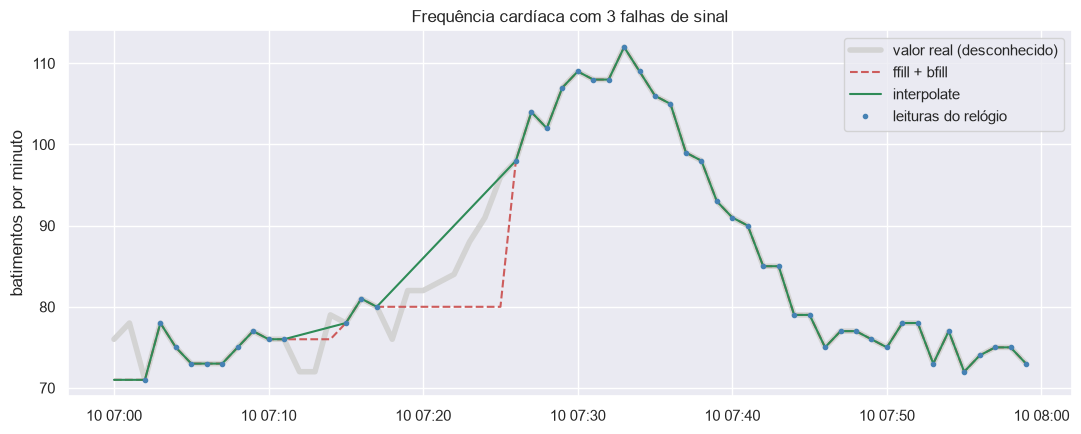

In [27]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(bpm.index, bpm, color="lightgray", linewidth=4, label="valor real (desconhecido)")
ax.plot(bpm.index, bpm_falhas.ffill().bfill(), color="indianred", linestyle="--", label="ffill + bfill")
ax.plot(bpm.index, bpm_falhas.interpolate(limit_direction="both"), color="seagreen", label="interpolate")
ax.plot(bpm_falhas.index, bpm_falhas, "o", color="steelblue", markersize=3, label="leituras do relógio")
ax.set_title("Frequência cardíaca com 3 falhas de sinal")
ax.set_ylabel("batimentos por minuto")
ax.legend()
plt.tight_layout()
plt.show()

### 5.3 Intervalos irregulares: `method="time"`
A interpolação padrão considera que os pontos estão **igualmente espaçados**. Se as medições têm intervalos diferentes, use `method="time"`, que leva em conta **quanto tempo** passou entre elas (exige um índice de datas).

In [28]:
temperatura = pd.Series([20.0, np.nan, 30.0],
                        index=pd.to_datetime(["2026-03-10 08:00", "2026-03-10 08:01", "2026-03-10 08:10"]))
pd.DataFrame({
    "original": temperatura,
    "linear (por posição)": temperatura.interpolate(),
    "time (por tempo)": temperatura.interpolate(method="time"),
})

,original,linear (por posição),time (por tempo)
2026-03-10 08:00:00,20.0,20.0,20.0
2026-03-10 08:01:00,NaN,25.0,21.0
2026-03-10 08:10:00,30.0,30.0,30.0


A leitura das 08:01 está **1 minuto** depois da primeira e **9 minutos** antes da última. O método `linear` ignora isso e coloca 25 (o meio); o `time` coloca 21, bem mais perto do valor das 08:00.

## Parte 6: Quando NÃO preencher

Às vezes o nulo **é a informação**. Exemplo: uma tabela de assinaturas em que `data_cancelamento` vazia quer dizer "o cliente **ainda é assinante**".

In [29]:
assinaturas = pd.DataFrame({
    "cliente_id": [1, 2, 3, 4, 5],
    "data_inicio": pd.to_datetime(["2025-01-10", "2025-03-05", "2025-06-20", "2025-08-01", "2025-11-15"]),
    "data_cancelamento": pd.to_datetime(["2025-07-10", None, "2026-01-20", None, None]),
})
assinaturas

,cliente_id,data_inicio,data_cancelamento
0,1,2025-01-10,2025-07-10
1,2,2025-03-05,NaT
2,3,2025-06-20,2026-01-20
3,4,2025-08-01,NaT
4,5,2025-11-15,NaT


Se preenchermos `data_cancelamento` com a mediana das datas (como faríamos com um número qualquer), **três clientes ativos passariam a constar como cancelados**. O certo é transformar o nulo numa informação explícita:

In [30]:
hoje = pd.Timestamp("2026-03-01")
assinaturas["ativo"] = assinaturas["data_cancelamento"].isna()

# Para calcular a duração, o "fim" de quem está ativo é hoje (uma decisão consciente e documentada)
fim = assinaturas["data_cancelamento"].fillna(hoje)
assinaturas["meses_de_assinatura"] = ((fim - assinaturas["data_inicio"]).dt.days / 30.44).round(1)
assinaturas

,cliente_id,data_inicio,data_cancelamento,ativo,meses_de_assinatura
0,1,2025-01-10,2025-07-10,False,5.9
1,2,2025-03-05,NaT,True,11.9
2,3,2025-06-20,2026-01-20,False,7.0
3,4,2025-08-01,NaT,True,7.0
4,5,2025-11-15,NaT,True,3.5


Repare: a coluna `data_cancelamento` **continua com os nulos**. Só usamos um preenchimento temporário (`fim`) para uma conta específica.

**Outros nulos que não se preenchem:** "nota da prova" de quem ainda não fez a prova, "data de alta" de paciente internado, "motivo da devolução" de pedido não devolvido.

## Parte 7: Duplicados: qual registro manter?

No Tutorial 1 você removeu linhas idênticas com `drop_duplicates()`. Na prática, a dúvida mais comum é outra: **o mesmo cliente aparece várias vezes, com dados diferentes. Qual linha fica?**

In [31]:
cadastro = pd.DataFrame({
    "cliente_id": [101, 102, 101, 103, 102, 101, 104, 104],
    "email": ["ana@ex.com", "bia@ex.com", "ana.nova@ex.com", "caio@ex.com",
              "bia@ex.com", "ana.nova@ex.com", "davi@ex.com", "davi@ex.com"],
    "cidade": ["Curitiba", "Londrina", "Curitiba", "Maringá", "Londrina", "Cascavel", "Curitiba", "Curitiba"],
    "atualizado_em": pd.to_datetime(["2026-01-05", "2026-01-07", "2026-02-10", "2026-01-20",
                                     "2026-01-07", "2026-03-01", "2026-02-02", "2026-02-02"]),
})
cadastro

,cliente_id,email,cidade,atualizado_em
0,101,ana@ex.com,Curitiba,2026-01-05
1,102,bia@ex.com,Londrina,2026-01-07
2,101,ana.nova@ex.com,Curitiba,2026-02-10
3,103,caio@ex.com,Maringá,2026-01-20
4,102,bia@ex.com,Londrina,2026-01-07
5,101,ana.nova@ex.com,Cascavel,2026-03-01
6,104,davi@ex.com,Curitiba,2026-02-02
7,104,davi@ex.com,Curitiba,2026-02-02


### 7.1 Duplicados exatos × duplicados pela chave

In [32]:
print("Linhas idênticas repetidas:       ", cadastro.duplicated().sum())
print("Clientes repetidos (pela chave):  ", cadastro.duplicated(subset=["cliente_id"]).sum())

Linhas idênticas repetidas:        2
Clientes repetidos (pela chave):   4


Só 2 linhas são **idênticas** (Bia e Davi), mas há 4 repetições do **mesmo cliente**: a Ana aparece 3 vezes, com e-mail e cidade diferentes.

### 7.2 O parâmetro `keep`
| `keep` | Quais repetições são marcadas como duplicadas |
|---|---|
| `"first"` (padrão) | todas, **menos a primeira** (a primeira fica) |
| `"last"` | todas, **menos a última** (a última fica) |
| `False` | **todas** as ocorrências (ninguém fica) |

In [33]:
pd.DataFrame({
    "cliente_id": cadastro["cliente_id"],
    "first": cadastro.duplicated(subset="cliente_id", keep="first"),
    "last": cadastro.duplicated(subset="cliente_id", keep="last"),
    "False": cadastro.duplicated(subset="cliente_id", keep=False),
})

,cliente_id,first,last,False
0,101,False,True,True
1,102,False,True,True
2,101,True,True,True
3,103,False,False,False
4,102,True,False,True
5,101,True,False,True
6,104,False,True,True
7,104,True,False,True


O `keep=False` é útil para **ver todos os casos problemáticos juntos** antes de decidir:

In [34]:
cadastro[cadastro.duplicated(subset="cliente_id", keep=False)].sort_values(["cliente_id", "atualizado_em"])

,cliente_id,email,cidade,atualizado_em
0,101,ana@ex.com,Curitiba,2026-01-05
2,101,ana.nova@ex.com,Curitiba,2026-02-10
5,101,ana.nova@ex.com,Cascavel,2026-03-01
1,102,bia@ex.com,Londrina,2026-01-07
4,102,bia@ex.com,Londrina,2026-01-07
6,104,davi@ex.com,Curitiba,2026-02-02
7,104,davi@ex.com,Curitiba,2026-02-02


### 7.3 Manter o registro mais recente

### 🔍 Passo a passo
1. `sort_values("atualizado_em")` coloca as linhas em ordem de data.
2. `drop_duplicates(subset="cliente_id", keep="last")` mantém, para cada cliente, a **última** linha, que agora é a **mais recente**.

**Sem ordenar antes, "a última" é só a última na ordem do arquivo**, que pode não ter nada a ver com a data.

In [35]:
mais_recente = (cadastro.sort_values("atualizado_em")
                        .drop_duplicates(subset="cliente_id", keep="last")
                        .sort_values("cliente_id"))
mais_recente

,cliente_id,email,cidade,atualizado_em
5,101,ana.nova@ex.com,Cascavel,2026-03-01
4,102,bia@ex.com,Londrina,2026-01-07
3,103,caio@ex.com,Maringá,2026-01-20
7,104,davi@ex.com,Curitiba,2026-02-02


### 7.4 Chave composta
Às vezes **uma coluna só não identifica** o registro. Numa rede de lojas, a nota fiscal 1001 pode existir na loja A **e** na loja B. A chave é o **par** (loja, número da nota).

In [36]:
notas = pd.DataFrame({
    "loja": ["A", "A", "B", "B", "A"],
    "numero_nota": [1001, 1002, 1001, 1003, 1001],
    "valor": [150.0, 89.9, 230.0, 45.5, 150.0],
})
print("Usando só o número da nota:", notas.duplicated(subset=["numero_nota"]).sum(), "duplicados (errado!)")
print("Usando loja + número:      ", notas.duplicated(subset=["loja", "numero_nota"]).sum(), "duplicado (certo)")
notas.drop_duplicates(subset=["loja", "numero_nota"])

Usando só o número da nota: 2 duplicados (errado!)
Usando loja + número:       1 duplicado (certo)


,loja,numero_nota,valor
0,A,1001,150.0
1,A,1002,89.9
2,B,1001,230.0
3,B,1003,45.5


## Parte 8: Validar o preenchimento

Todo preenchimento **muda os dados**. Antes de seguir, confira o que mudou.

### 8.1 Comparar as distribuições
Preencher com valores "do meio" sempre **reduz a variação** (o desvio-padrão), porque acrescenta valores típicos. Se a redução for grande, as análises vão parecer mais "certinhas" do que a realidade [3].

In [37]:
pd.DataFrame({
    "renda antes (sem os nulos)": renda_original.describe(),
    "renda depois de preencher": df["renda"].describe(),
}).round(0)

,renda antes (sem os nulos),renda depois de preencher
count,453.0,554.0
mean,4849.0,4860.0
std,1803.0,1638.0
min,1560.0,1560.0
25%,3620.0,3822.0
50%,4580.0,4690.0
75%,5770.0,5440.0
max,13150.0,13150.0


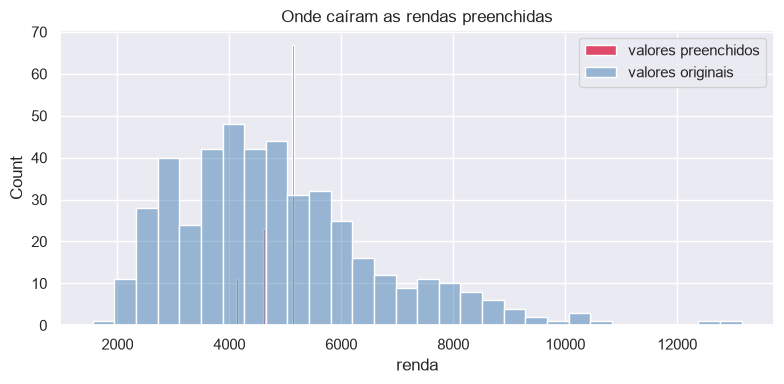

In [38]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(df.loc[df["renda_faltava"], "renda"], bins=30, color="crimson", label="valores preenchidos", ax=ax)
sns.histplot(renda_original.dropna(), bins=30, color="steelblue", alpha=0.5, label="valores originais", ax=ax)
ax.set_title("Onde caíram as rendas preenchidas")
ax.legend()
plt.tight_layout()
plt.show()

### Como ler
- Os valores preenchidos (vermelho) se concentram em **poucos valores**: só 3 medianas, uma por faixa etária. É o preço do preenchimento simples.
- O desvio-padrão caiu um pouco. Com poucos nulos, tudo bem; com muitos, considere técnicas mais avançadas, como a **imputação múltipla** [3], que fogem do escopo deste tutorial.

### 8.2 Provar com `assert`

In [39]:
assert df[["idade", "renda", "num_filhos", "cidade", "escolaridade", "satisfacao"]].notna().all().all()
assert df["renda_faltava"].sum() == renda_original.isna().sum(), "A coluna indicadora não bate"
assert df["num_filhos"].dtype == "Int64"
assert df["escolaridade"].cat.ordered
assert "observacao" not in df.columns and "apelido" not in df.columns
assert df["cliente_id"].is_unique
print("Todas as validações passaram! ✅")

Todas as validações passaram! ✅


## Parte 9: Exercícios

Tente sozinho antes de olhar as dicas. Recarregue `pesquisa_clientes.csv` para começar do zero.

1. **Tipos de nulo:** crie `pd.Series([1, None, 3])` e `pd.Series([1, None, 3], dtype="Int64")`. Qual é o `dtype` de cada uma e como o nulo aparece?
2. **Diagnóstico:** a falta de `escolaridade` depende da `cidade`? Calcule o % de nulos de escolaridade por cidade. *(Dica: `df["escolaridade"].isna().groupby(df["cidade"]).mean()`.)*
3. **thresh:** quantas linhas sobram com `dropna(thresh=8)` na pesquisa original? E com `thresh=10`?
4. **Discreta:** preencha `num_filhos` com a mediana **arredondada** e compare a contagem de cada valor com a do preenchimento pela moda.
5. **Ordinal:** faça para `satisfacao` o mesmo que fizemos com `escolaridade` (Parte 4.4), usando a lista `satisfacoes` como ordem.
6. **Séries de tempo:** preencha `bpm_falhas` com `interpolate(limit=2)` e conte quantos nulos sobram. Em quais falhas?
7. **Duplicados:** no `cadastro`, mantenha o registro **mais antigo** de cada cliente.
8. **Desafio:** esconda 30 valores **conhecidos** de `bpm` (escolha posições ao acaso), preencha com `ffill` e com `interpolate` e calcule o erro médio de cada um. O resultado confirma a Parte 5?

---

### Resumo do fluxo (cole na parede! 📌)

1. **Reconhecer os nulos**: `isna()` (nunca `== np.nan`); inteiros com nulo → `Int64`
2. **Diagnosticar**: nulos por coluna e por linha, `isna().corr()`, comparar grupos com e sem o dado
3. **Apagar com critério**: `dropna(axis=1, how="all")`, `thresh`, `subset`; coluna com mais de 50% de nulos sai
4. **Marcar antes de preencher**: `df["x_faltava"] = df["x"].isna()`
5. **Preencher pelo tipo**: contínua → mediana (por grupo, se MAR); discreta → moda; nominal → "Desconhecido"; ordinal → mediana da posição
6. **Séries de tempo**: `interpolate()` (ou `ffill().bfill()`), com `limit`
7. **Nulo com significado**: não preencher; criar uma coluna que explique
8. **Duplicados**: ordenar e escolher `keep`; usar a chave certa (às vezes composta)
9. **Validar**: comparar distribuições e usar `assert`

---

## Referências

**Dados faltantes**
- [1] Rubin, D. B. (1976). Inference and Missing Data. *Biometrika*, 63(3), 581–592.
- [2] Little, R. J. A., & Rubin, D. B. (2019). *Statistical Analysis with Missing Data* (3ª ed.). Wiley.
- [3] van Buuren, S. (2018). *Flexible Imputation of Missing Data* (2ª ed.). CRC Press. Gratuito em https://stefvanbuuren.name/fimd/
- [4] Schafer, J. L., & Graham, J. W. (2002). Missing Data: Our View of the State of the Art. *Psychological Methods*, 7(2), 147–177.

**Tipos de variável**
- [5] Stevens, S. S. (1946). On the Theory of Scales of Measurement. *Science*, 103(2684), 677–680.

**Ferramentas**
- [6] McKinney, W. (2022). *Python for Data Analysis* (3ª ed.). O'Reilly. Gratuito em https://wesmckinney.com/book/

### 📖 Para continuar estudando (gratuitos)
- *Flexible Imputation of Missing Data*, de van Buuren [3]: capítulos 1 e 2 explicam por que o preenchimento simples tem limites.
- Documentação do pandas, "Working with missing data": https://pandas.pydata.org/docs/user_guide/missing_data.html